### [GALT] Vežba 2: Sintetička populacija zvezda

### <font color='yellow'>Ideja vežbe: Generisanje sintetičke populacije zvezda koristeći inicijalnu funkciju mass (initial mass function) i analiziranje Malmkvistove neobjektivnosti.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod


Statističko opisivanje zvezdanih populacija u astrofizici temelji se na dva ključna teorijska koncepta: raspodeli masa pri rođenju i rezultujućoj raspodeli luminoznosti.
1. Inicialna funkcija mase (_initial mass function_) definiše relativnu zastupljenost zvezda po jediničnom intervalu mase u trenutku njihovog formiranja. Prema empirijskom Salpeterovom zakonu (1955), ova raspodela prati funkciju stepenog zakona:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
Ovaj odnos ukazuje na izrazitu dominaciju zvezda malih masa u poređenju sa masivnim objektima.
Naravno, postoji mnogo modernijih IMF, npr. Miller-Scalo IMF, Chabrier IMF, ali u ovoj vežbi, jednostavnosti radi, koristićemo prvu predloženu. (https://articles.adsabs.harvard.edu/pdf/1955ApJ...121..161S)

2. Dok IMF opisuje maseni spektar, funkcija luminoznosti (LF) kvantifikuje gustinu broja zvezda po jedinici zapremine u opsegu određenog sjaja ili magnitude. Prelaz sa mase na luminoznost ostvaruje se putem relacije masa-luminoznost ($L \propto M^{3.5}$ za zvezde glavnog niza), čime se teorijske mase prevode u posmatračke veličine — apsolutne magnitude. U posmatračkoj astrofizici, poznavanje funkcije luminoznosti je neophodno za modelovanje efekata selekcije i ispravnu rekonstrukciju prostorne distribucije zvezdanih sistema.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

##### <font color="green">1. Semplovati 10000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Hint: Učili ste na astrostatistici kako se to radi, inverse transform sampling.)</font>

In [14]:
random = np.random.default_rng(42)

alfa = 2.35
M_min, M_max = 0.08, 200 # u masama sunca
N = 10000

u = random.random(N)
e = 1- alfa
M = (M_min**e + u * (M_max**e - M_min**e))**(1/e)

print(M)

[0.24067841 0.12273466 0.34066809 ... 0.09146018 0.11310137 0.13002063]


ITS za stepeni zakon ce dati analiticki inversni CDF (izvukli na tabli na predavanju), pa je semplovanje direktno.

##### <font color="green">2. Odrediti luminoznost i apsolutnu magnitudu svih zvezda.</font>

In [61]:
M_sunce_abs = 4.74 # apsolutna bolometrijska mag Sunca
L = M**3.5 
M_abs = M_sunce_abs - 2.5*np.log10(L)

print("L =", L)
print("M_abs =", M_abs)
print(np.median(M_abs))

L = [0.00683959 0.00064772 0.02307598 ... 0.00023137 0.00048656 0.00079258]
M_abs = [10.15242511 12.71153688  8.83209972 ... 13.82921947 13.02215627
 12.49239274]
12.396460555479848


Zbog odnosa $L \propto M^{3.5}$ raspon masa od ~3 reda velicine prelazi u raspon luminoznosti od ~12 redova velicine. Vecina zvezda su slabe patuljaste zvezde jer vidimo da je medijana od apsolutne magnitude svih zvezda 12.4, a sjajne zvezde su veoma retke.

##### <font color="green">3. Pretpostavljajući da je maksimalna udaljenost zvezda 10kpc, i da su uniformno raspoređene u sferi, semplovati njihove udaljenosti i odrediti prividne magnitude i prikazati histogram (m).</font>

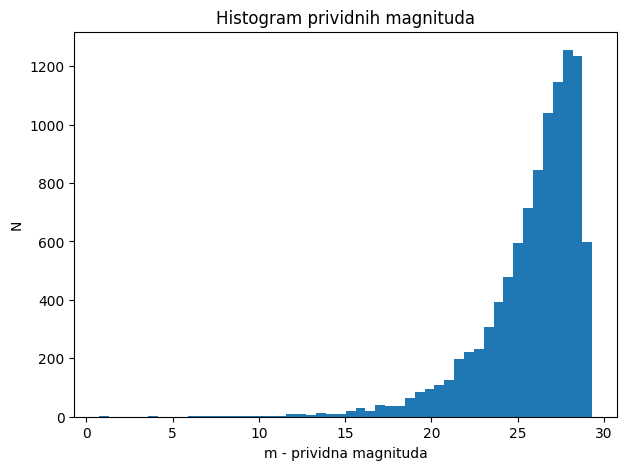

[24.07534168 26.64550213 23.38742246 ... 27.52345796 27.86125151
 27.10584203]


In [27]:
R_max = 10000 # 10kpc u pc
d = R_max * random.random(N)**(1/3)
m = M_abs + 5*np.log10(d) - 5

plt.figure(figsize = (7,5))
plt.hist(m, bins=50)
plt.title("Histogram prividnih magnituda")
plt.ylabel("N")
plt.xlabel("m - prividna magnituda")
plt.show()

print(m)

Prividna magnituda racunata je iz modula udaljenosti. Jasno se vidi da je vecina zvezda slabe magnitude sto je uzrok 2 stvari: ima mnogo slabih zvezda u pogledu luminoznosti sto smo zakljucili iz prethodnog zadatka i am volumenski efekat a to je da je postoji mnogo udaljenih zvezda.

##### <font color="green">4. Analizirati kako se menja broj detektovanih zvezda u zavisnosti od udaljenosti za maksimalnu prividnu magnitudu koja može biti detektovana od 15, 18 i 22.</font>

In [69]:
m_detektovani = [15, 18, 22]

for granica in m_detektovani:
    det = m <= granica
    print(f"m = {granica}: detektovano = {det.sum()}")

m = 15: detektovano = 82
m = 18: detektovano = 236
m = 22: detektovano = 991


Udeo detektovanih zvezda naglo opada sa ualjenoscu, jer flux opada kao $\frac{1}{d^2}$. Samim tim pomeranje granice od 15 do 22 povecava broj detektovanih zvezda ~12 puta jer je dubina pregleda ogranicena na 10kpc, te dodatna osetljivost donosi slabije zvezde a ne veci volumen njih

##### <font color="green">5. Prikazati grafike zavisnosti apsolutne magnitude od udaljenosti i označiti različitim simbolima detektovane i nedektovane zvezde, za sve tri granične magnitude. (Malmkvistova neobjektivnost)</font>

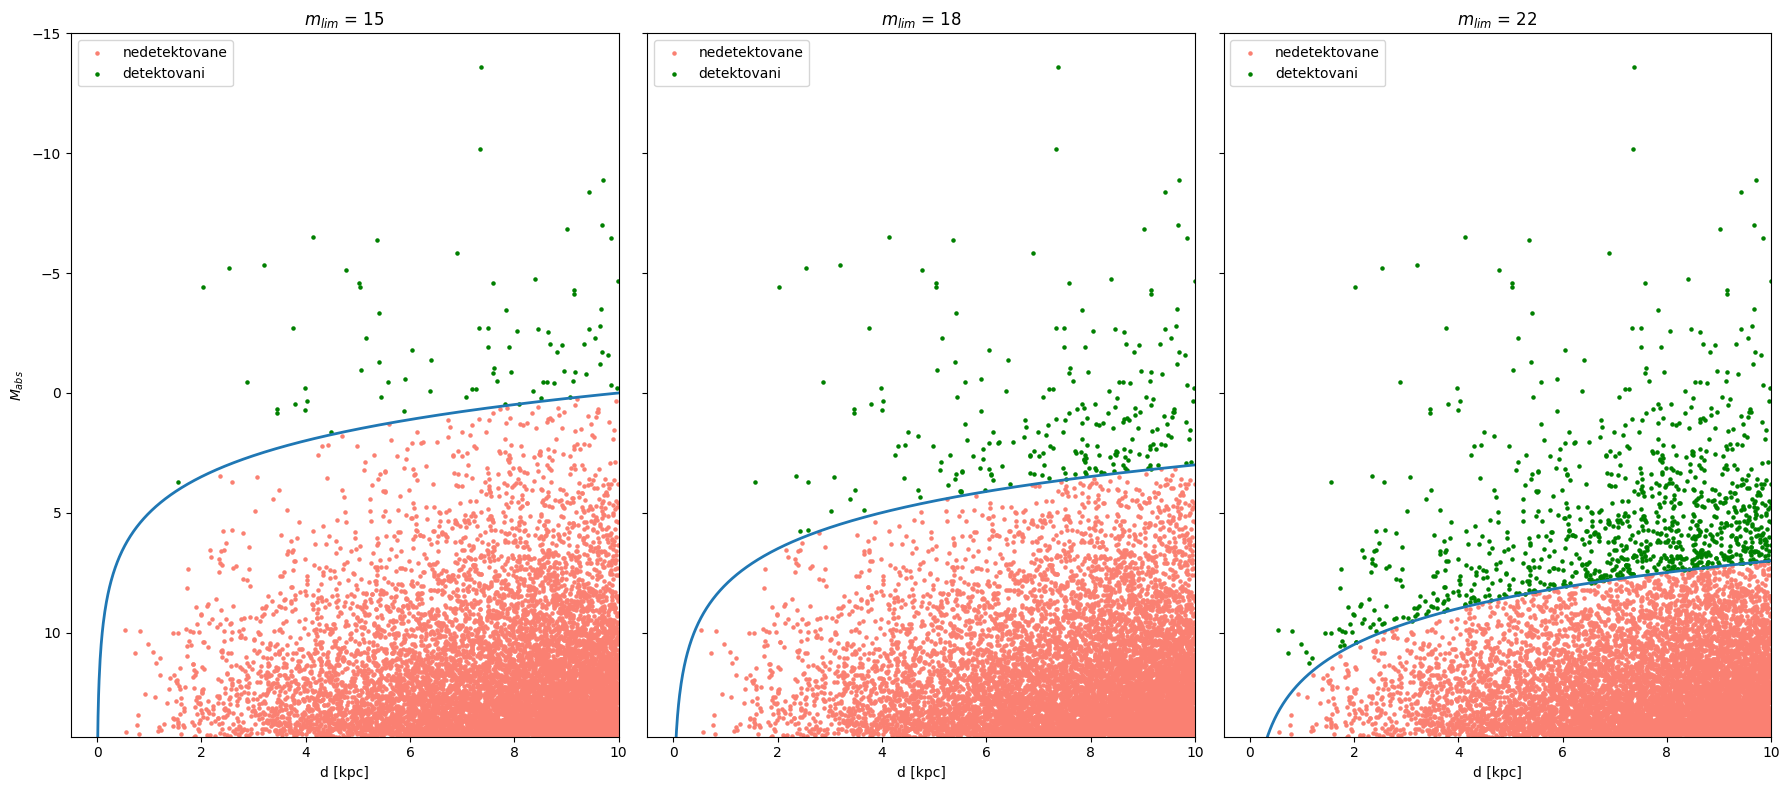

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(18,8), sharey=True)
for ax, granica in zip(axes, m_detektovani):
    det = m <= granica
    ax.scatter(d[~det]/1000, M_abs[~det], c='salmon', label='nedetektovane', s=5)
    ax.scatter(d[det]/1000, M_abs[det], c='green', label='detektovani', s=5)

    # granica detekcije
    dd = np.linspace(0.0001, R_max, 1000)
    ax.plot(dd/1000, granica - 5*np.log10(dd) + 5, lw=2)
    ax.set_title(f'$m_{{lim}}$ = {granica}')
    ax.set_xlabel('d [kpc]')
    ax.set_xlim(-0.5,10)
    ax.set_ylim(M_abs.max(), -15)
    ax.legend(loc='best')
axes[0].set_ylabel(f'$M_{{abs}}$')
plt.tight_layout()
plt.show()

Puna linija je granica detekcije, $ M_{abs} = m_{lim} - 5*log(d) + 5 $. Detektovane su samo zvezde iznad nje (zeleno), a sve ispod su nedetektovane (crveno). Sto je zvezda dalja, to mora biti sjajnija da bi bila vidljiva. Na 10 kpc granica iznosi $M_{abs} \approx 0$ za $m_{lim}=15$, $\approx +3$ za $m_{lim}=18$ i $\approx +7$ za $m_{lim}=22$. Povecanjem $m_{lim}$ granica se spusta ka slabijim zvezdama, ali uvek ostaje rastuca funkcija udaljenosti. Sa porastom udaljenosti uzorak detektovanih zvezda sve vise cine samo luminozne zvezde. Sto je direktno Malmkvistova neobjektivnost: uzorak ogranicen magnitudom sistematski je obogacen sjajnim zvezdama u odnosu na pravu populaciju. Samim tim funkcija luminoznosti ili srednja luminoznost procenjena direktno iz ovakvog uzorka bila bi pogresna, u ovom slucaju precenjena.